# 模块 1 · 行为与留存分析

数据来源：`ecommerce_analysis` 库里阶段 1 SQL 产出的 `analysis_*` 结果表（REES46 多品类电商行为数据，2019-10 ~ 2019-11 抽样）。

本 notebook 只做**读取 + 可视化 + 结论**，不重算指标——重计算都在 `sql/` 里完成。

顺序：行为分布 → 转化漏斗 → 加购流失 → 用户留存 → 复购留存 → RFM 分层。


In [1]:
import os
os.environ['MYSQL_PWD']='a123456'

In [2]:
import os, getpass
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

# ============ 统一专业制图风格 ============
INK, MUTED, GRID = '#22333B', '#6B7A82', '#E8EAED'
PRIMARY, ACCENT = '#2A6F97', '#E07A5F'
FUNNEL_COLORS = ['#2A6F97', '#468FAF', '#89C2D9']

mpl.rcParams.update({
    'figure.facecolor': 'white', 'axes.facecolor': 'white', 'savefig.facecolor': 'white',
    'figure.dpi': 110, 'savefig.dpi': 150,
    'font.sans-serif': ['Microsoft YaHei', 'SimHei', 'DejaVu Sans'],  # 中文不显示成方块
    'axes.unicode_minus': False,
    'axes.edgecolor': MUTED, 'axes.labelcolor': INK, 'text.color': INK,
    'xtick.color': MUTED, 'ytick.color': MUTED,
    'axes.grid': True, 'axes.axisbelow': True, 'grid.color': GRID, 'grid.linewidth': 0.9,
    'axes.spines.top': False, 'axes.spines.right': False,
    'font.size': 11, 'legend.frameon': False,
})

def titled(ax, title, subtitle=None):
    """左对齐主标题 + 灰色副标题（编辑风），替代默认居中 title。"""
    ax.set_title('')
    ax.text(0, 1.07, title, transform=ax.transAxes, fontsize=14, fontweight='bold', va='bottom')
    if subtitle:
        ax.text(0, 1.015, subtitle, transform=ax.transAxes, fontsize=10, color=MUTED, va='bottom')

def kmfmt(x, _pos=None):
    """大数字转 K / M（保留必要的一位小数，避免 1.5K 被取整成 2K 与 2K 重复）。"""
    if x >= 1e6:
        return f'{x/1e6:.1f}M'
    if x >= 1e3:
        return f'{x/1e3:.1f}'.rstrip('0').rstrip('.') + 'K'
    return f'{x:.0f}'

print('环境就绪  pandas', pd.__version__, '| numpy', np.__version__)

环境就绪  pandas 2.3.3 | numpy 2.2.5


In [3]:
# 数据源开关：USE_DB=True 直连 MySQL；=False 则读 reports/sql_outputs 下导出的 CSV（无需数据库密码）
USE_DB = True

PROJECT_DIR = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
CSV_DIR = PROJECT_DIR / 'reports' / 'sql_outputs'
FIG_DIR = PROJECT_DIR / 'reports' / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)

DB = dict(host='127.0.0.1', port=3306, user='root', database='ecommerce_analysis')
_engine = None

def _get_engine():
    global _engine
    if _engine is None:
        from sqlalchemy import create_engine
        pwd = os.environ.get('MYSQL_PWD') or getpass.getpass('MySQL 密码: ')
        url = f"mysql+pymysql://{DB['user']}:{pwd}@{DB['host']}:{DB['port']}/{DB['database']}?charset=utf8mb4"
        _engine = create_engine(url)
    return _engine

def load(table):
    """读一张分析结果表为 DataFrame。"""
    if USE_DB:
        return pd.read_sql(f'SELECT * FROM {table}', _get_engine())
    return pd.read_csv(CSV_DIR / f'{table}.csv')

def savefig(name):
    """把当前图保存到 reports/figures，供报告 / README 用。"""
    plt.savefig(FIG_DIR / f'{name}.png', bbox_inches='tight')

print('数据源:', 'MySQL' if USE_DB else f'CSV @ {CSV_DIR}')

数据源: MySQL


## 1. 行为分布
各行为类型的事件量与占比，先看清数据的整体构成。

,event_type,events,users,sessions,event_share
0,view,1051941,53274,231394,0.949362
1,cart,38919,10597,23307,0.035124
2,purchase,17190,7096,14481,0.015514


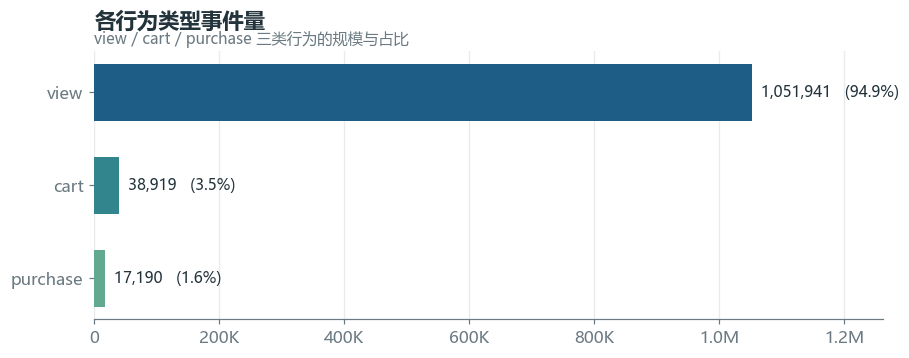

In [4]:
ev = load('analysis_event_distribution').sort_values('events')
ev['event_share'] = ev['events'] / ev['events'].sum()
display(ev.sort_values('events', ascending=False).reset_index(drop=True))

fig, ax = plt.subplots(figsize=(8.5, 3.4))
colors = sns.color_palette('crest', len(ev))
ax.barh(ev['event_type'], ev['events'], color=colors, height=0.62, zorder=3)
for y, (v, s) in enumerate(zip(ev['events'], ev['event_share'])):
    ax.text(v, y, f'  {v:,.0f}   ({s:.1%})', va='center', ha='left', fontsize=10, color=INK)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(kmfmt))
ax.set_xlim(0, ev['events'].max() * 1.2)
ax.grid(axis='y', visible=False)
sns.despine(ax=ax, left=True)
titled(ax, '各行为类型事件量', 'view / cart / purchase 三类行为的规模与占比')
plt.tight_layout(); savefig('01_event_distribution'); plt.show()

## 2. 转化漏斗
- **无序总览漏斗**（`funnel_overview`）：曾浏览 / 曾加购 / 曾购买，各独立人数。
- **用户级严格漏斗**（`funnel_user`）：按 view → cart → purchase 有序，更贴近真实路径转化。

> 注意：本数据集大量购买没有前置加购事件，所以严格漏斗的购买人数会明显低于实际买家数，解读时以\"加购路径转化\"理解。

—— 无序总览漏斗 ——


,stage_order,stage,users,share_of_all_users
0,1,view,53274.0,0.9999
1,2,cart,10597.0,0.1989
2,3,purchase,7096.0,0.1332


—— 用户级严格漏斗 ——


,stage_order,stage,users,previous_stage_rate,view_to_stage_rate
0,1,view,53274.0,1.0000,1.0000
1,2,cart_after_view,10575.0,0.1985,0.1985
2,3,purchase_after_cart,4729.0,0.4472,0.0888


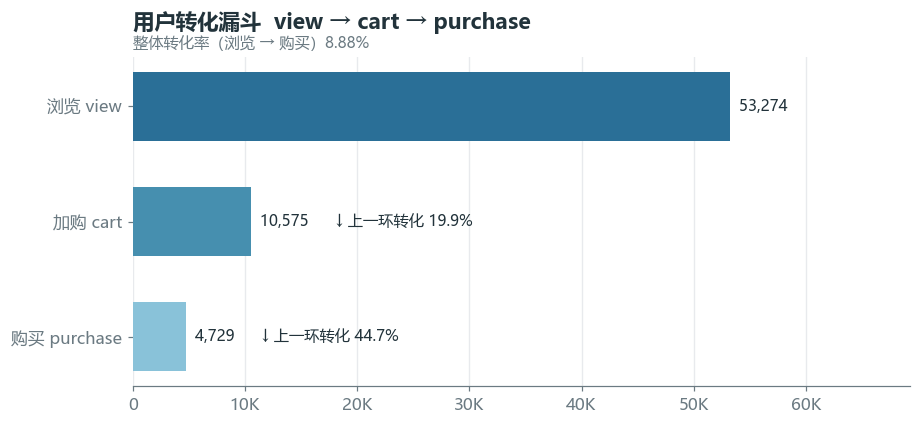

In [5]:
fo = load('analysis_funnel_overview').sort_values('stage_order')
fu = load('analysis_funnel_user').sort_values('stage_order')
print('—— 无序总览漏斗 ——'); display(fo)
print('—— 用户级严格漏斗 ——'); display(fu)

labels_cn = ['浏览 view', '加购 cart', '购买 purchase']
vals = fu['users'].tolist()

fig, ax = plt.subplots(figsize=(8.5, 4))
y = list(range(len(vals)))
ax.barh(y, vals, color=FUNNEL_COLORS, height=0.6, zorder=3)
ax.set_yticks(y); ax.set_yticklabels(labels_cn[:len(vals)]); ax.invert_yaxis()
for i, v in enumerate(vals):
    conv = '' if i == 0 else f'      ↓ 上一环转化 {vals[i] / vals[i-1]:.1%}'
    ax.text(v, i, f'  {v:,.0f}{conv}', va='center', ha='left', fontsize=10, color=INK)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(kmfmt))
ax.set_xlim(0, vals[0] * 1.3)
ax.grid(axis='y', visible=False)
sns.despine(ax=ax, left=True)
overall = vals[-1] / vals[0] if vals[0] else 0
titled(ax, '用户转化漏斗  view → cart → purchase', f'整体转化率（浏览 → 购买）{overall:.2%}')
plt.tight_layout(); savefig('02_funnel_user'); plt.show()

## 3. 加购流失（辅助观察）
加购用户里有多少又把商品移出了购物车，以及移出后是否仍然购买。

> 本数据集（多品类商店）没有 `remove_from_cart` 行为，此段大概率为 0 / 空，属正常，可在结论中说明后跳过。

In [6]:
cr = load('analysis_cart_remove_summary'); display(cr)
r = cr.iloc[0]
print(f"加购用户            : {r['cart_users']:,.0f}")
print(f"其中移出过购物车     : {r['cart_users_with_remove']:,.0f}  （占加购用户 {r['remove_among_cart_users_rate']:.1%}）")
print(f"移出后仍然购买       : {r['removed_but_purchased_users']:,.0f}")

,cart_users,cart_users_with_remove,remove_among_cart_users_rate,removed_but_purchased_users
0,10597.0,0.0,0.0,0.0


加购用户            : 10,597
其中移出过购物车     : 0  （占加购用户 0.0%）
移出后仍然购买       : 0


## 4. 用户留存
按用户首次活跃日分组（cohort），看次日 / 7 日 / 30 日留存，以及 1-14 天留存热力图。

,cohort_date,cohort_users,d1_users,d1_retention,d7_users,d7_retention,d30_users,d30_retention
0,2019-10-01,1919,341,0.1777,246,0.1282,162,0.0844
1,2019-10-02,1491,202,0.1355,151,0.1013,119,0.0798
2,2019-10-03,1281,194,0.1514,110,0.0859,88,0.0687
3,2019-10-04,1420,153,0.1077,114,0.0803,94,0.0662
4,2019-10-05,1276,139,0.1089,96,0.0752,73,0.0572


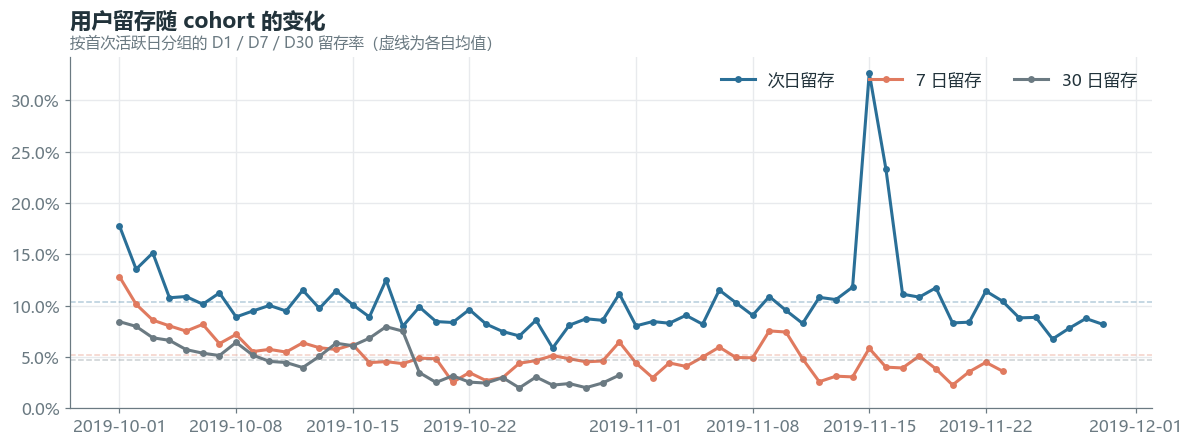

In [7]:
rc = load('analysis_retention_cohort_summary').sort_values('cohort_date')
rc['cohort_date'] = pd.to_datetime(rc['cohort_date'])
display(rc.head())

fig, ax = plt.subplots(figsize=(11, 4.2))
series = [('d1_retention', '次日留存', PRIMARY), ('d7_retention', '7 日留存', ACCENT), ('d30_retention', '30 日留存', MUTED)]
for col, lab, c in series:
    ax.plot(rc['cohort_date'], rc[col], color=c, lw=2, marker='o', ms=3.5, label=lab)
    m = rc[col].mean()
    ax.axhline(m, color=c, lw=1, ls='--', alpha=0.35)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax.set_ylim(0, None)
ax.legend(loc='upper right', ncol=3)
sns.despine(ax=ax)
titled(ax, '用户留存随 cohort 的变化', '按首次活跃日分组的 D1 / D7 / D30 留存率（虚线为各自均值）')
plt.tight_layout(); savefig('03_retention_curve'); plt.show()

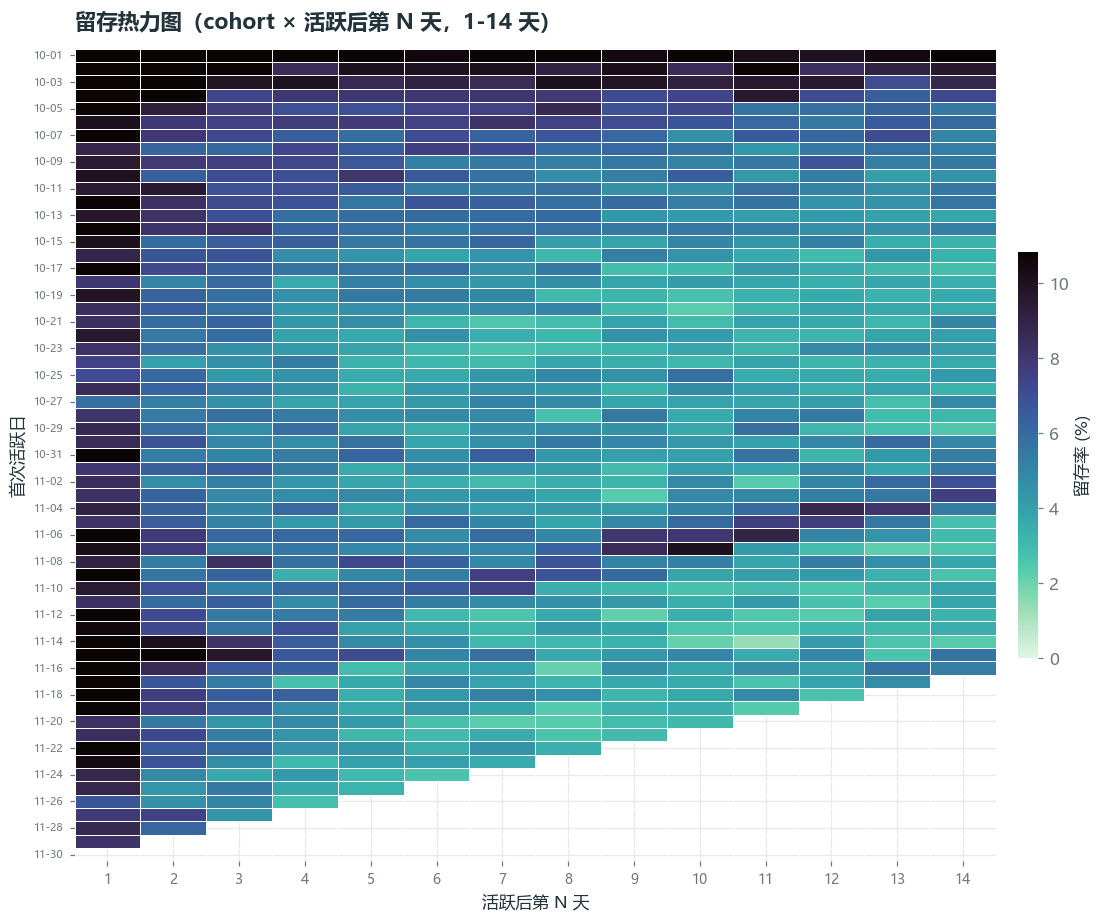

In [8]:
rm = load('analysis_retention_matrix_30d')
rm['cohort_date'] = pd.to_datetime(rm['cohort_date']).dt.strftime('%m-%d')
pivot = rm.pivot(index='cohort_date', columns='retention_day', values='retention_rate')
cols = [c for c in pivot.columns if 1 <= c <= 14]  # 去掉第 0 天（恒为 100%），聚焦留存衰减
# 用数据 96 分位定色阶上限，避免个别离群 cohort 把整体压暗
vmax = max(5.0, float(np.nanpercentile(pivot[cols].values * 100, 96)))

fig, ax = plt.subplots(figsize=(11, 8.5))
sns.heatmap(pivot[cols] * 100, cmap='mako_r', vmin=0, vmax=vmax, ax=ax,
            linewidths=0.4, linecolor='white',
            cbar_kws={'label': '留存率 (%)', 'shrink': 0.5, 'pad': 0.02})
ax.set_xlabel('活跃后第 N 天'); ax.set_ylabel('首次活跃日')
ax.tick_params(axis='y', labelsize=7, rotation=0)
ax.tick_params(axis='x', labelsize=9)
ax.text(0, 1.02, '留存热力图（cohort × 活跃后第 N 天，1-14 天）',
        transform=ax.transAxes, fontsize=14, fontweight='bold', va='bottom')
plt.tight_layout(); savefig('04_retention_heatmap'); plt.show()

## 5. 复购留存
首次购买后 D1 / D7 / D30 是否再次购买。

,purchase_cohort_date,purchase_users,d1_repurchase_users,d1_repurchase_rate,d7_repurchase_users,d7_repurchase_rate,d30_repurchase_users,d30_repurchase_rate
0,2019-10-01,140,16,0.1143,10,0.0714,7,0.0500
1,2019-10-02,141,12,0.0851,5,0.0355,2,0.0142
2,2019-10-03,113,15,0.1327,7,0.0619,4,0.0354
3,2019-10-04,151,13,0.0861,5,0.0331,6,0.0397
4,2019-10-05,153,3,0.0196,4,0.0261,5,0.0327
5,2019-10-06,155,12,0.0774,4,0.0258,0,0.0000
6,2019-10-07,118,6,0.0508,3,0.0254,2,0.0169
7,2019-10-08,114,6,0.0526,2,0.0175,3,0.0263
8,2019-10-09,117,4,0.0342,3,0.0256,1,0.0085
9,2019-10-10,110,9,0.0818,1,0.0091,2,0.0182


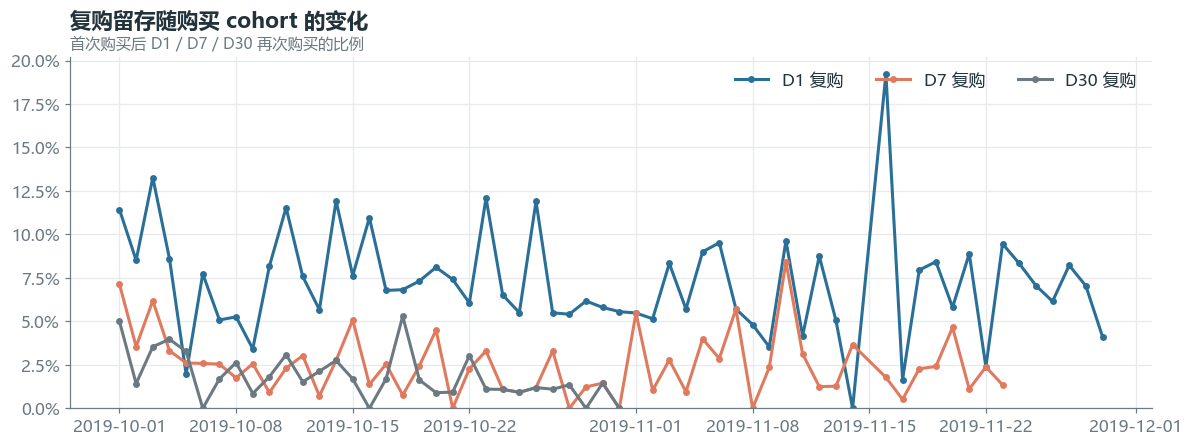

整体平均： D1 7.21% | D7 2.50% | D30 1.84%


In [9]:
rp = load('analysis_repurchase_retention').sort_values('purchase_cohort_date')
rp['purchase_cohort_date'] = pd.to_datetime(rp['purchase_cohort_date'])
display(rp.head(10))

fig, ax = plt.subplots(figsize=(11, 4.2))
for col, lab, c in [('d1_repurchase_rate', 'D1 复购', PRIMARY), ('d7_repurchase_rate', 'D7 复购', ACCENT), ('d30_repurchase_rate', 'D30 复购', MUTED)]:
    ax.plot(rp['purchase_cohort_date'], rp[col], color=c, lw=2, marker='o', ms=3.5, label=lab)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax.set_ylim(0, None); ax.legend(loc='upper right', ncol=3)
sns.despine(ax=ax)
titled(ax, '复购留存随购买 cohort 的变化', '首次购买后 D1 / D7 / D30 再次购买的比例')
plt.tight_layout(); savefig('05_repurchase_curve'); plt.show()

print('整体平均：',
      'D1', f"{rp['d1_repurchase_rate'].mean():.2%}",
      '| D7', f"{rp['d7_repurchase_rate'].mean():.2%}",
      '| D30', f"{rp['d30_repurchase_rate'].mean():.2%}")

## 6. RFM 用户分层
各分层的用户规模与消费额贡献——找出\"人少但贡献大\"的高价值群体。

,user_segment,users,user_ratio,segment_monetary,monetary_ratio,avg_recency_days,avg_frequency,avg_monetary
0,重要价值用户,949,0.1337,2119856.07,0.4098,8.57,4.92,2233.78
1,高消费潜力用户,816,0.1150,1123434.11,0.2172,25.67,2.60,1376.76
2,重要唤回用户,781,0.1101,877692.31,0.1697,42.20,3.08,1123.81
3,新近低频用户,1514,0.2134,438036.70,0.0847,9.99,1.00,289.32
4,一般用户,2031,0.2862,319875.58,0.0618,25.59,1.36,157.50
5,流失风险用户,1005,0.1416,293573.31,0.0568,53.67,1.00,292.11


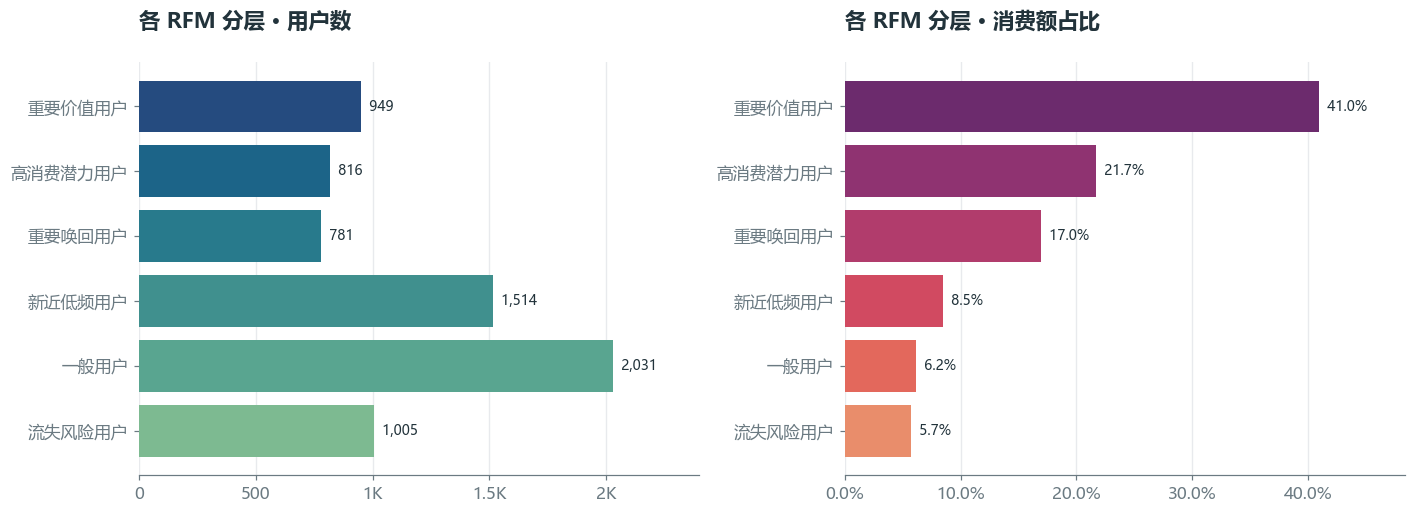

—— RFM 原始指标概览 ——


,purchase_users,min_recency_days,avg_recency_days,max_recency_days,min_frequency,avg_frequency,max_frequency,min_monetary,avg_monetary,max_monetary
0,7096,1,25.8,61,1,2.04,66,1.09,728.93,57481.85


In [10]:
seg = load('analysis_rfm_segment_summary').sort_values('segment_monetary')
display(seg.sort_values('segment_monetary', ascending=False).reset_index(drop=True))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
axes[0].barh(seg['user_segment'], seg['users'], color=sns.color_palette('crest', len(seg)), zorder=3)
for i, v in enumerate(seg['users']):
    axes[0].text(v, i, f'  {v:,.0f}', va='center', fontsize=9, color=INK)
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(kmfmt))
axes[0].set_xlim(0, seg['users'].max() * 1.18)
axes[0].grid(axis='y', visible=False); sns.despine(ax=axes[0], left=True)
titled(axes[0], '各 RFM 分层 · 用户数')

axes[1].barh(seg['user_segment'], seg['monetary_ratio'], color=sns.color_palette('flare', len(seg)), zorder=3)
for i, v in enumerate(seg['monetary_ratio']):
    axes[1].text(v, i, f'  {v:.1%}', va='center', fontsize=9, color=INK)
axes[1].xaxis.set_major_formatter(mticker.PercentFormatter(1.0))
axes[1].set_xlim(0, seg['monetary_ratio'].max() * 1.18)
axes[1].grid(axis='y', visible=False); sns.despine(ax=axes[1], left=True)
titled(axes[1], '各 RFM 分层 · 消费额占比')

plt.tight_layout(); savefig('06_rfm_segments'); plt.show()

print('—— RFM 原始指标概览 ——'); display(load('analysis_rfm_metric_summary'))

## 7. 结论与发现

> 数据为 2019-10 ~ 2019-11 的 1% 用户级抽样（53,274 名用户）。每条结论都指向后续模块。

**1. 行为构成 —— 重浏览、轻转化**
- 浏览（view）占全部事件的 **94.9%**（约 105 万次），加购仅 3.5%、购买 1.55%。
- 53,274 名用户中，加购 10,597 人（19.9%）、购买 7,096 人（**13.3%**）。
- → 流量充裕但转化稀薄，价值集中在少数动作上。

**2. 转化瓶颈 —— 卡在"浏览 → 加购"**
- 严格漏斗 view → cart → purchase：浏览→加购 **19.9%** 是最大流失点（约八成浏览用户从未加购）；加购→购买 **44.7%** 相对健康；整体浏览→购买 **8.88%**。
- 无序口径下 7,096 人购买，但仅 4,729 人走过加购路径 —— 约 **1/3 的买家直接下单、未加购**。
- → **浏览 → 加购**是最该做实验的环节，是模块 3 A/B 假设的来源（如商详页加购引导 / 限时提示能否提升 view→cart）。

**3. 留存表现 —— 首周快速流失**
- 次日留存 **10.4%**，7 日 **5.2%**（≈ 腰斩），30 日 **4.7%** 趋于平稳。
- → 流失集中在激活后头 7 天，干预窗口需前置；模块 2 把 D1/D7 留存设为监控指标，模块 4 的流失标签可参考"7 日未回访"。

**4. 复购情况 —— 以一次性购买为主**
- 首购后复购：D1 **7.2%**、D7 2.5%、D30 1.8%；人均购买频次仅 **2.04 次**。
- → 复购是 GMV 最大的增长空间，可作为后续运营 / 实验的重点方向。

**5. 高价值人群 —— 明显的二八结构**
- **重要价值用户 949 人（13.4%）贡献 41.0% 消费额**；前三层（重要价值 + 高消费潜力 + 重要唤回）合计 **35.9% 的用户撑起约 79.7% 的 GMV**。
- 重要价值用户：近度 8.6 天、频次 4.9、客单价 2,234，最活跃也最值钱。
- 另有 **流失风险用户 1,005 人（14.2%）**，近度 53.7 天、几乎不复购。
- → 模块 4 流失预测优先保护"重要价值 / 高消费潜力"；"重要唤回"（近度 42 天但历史频次高）是召回运营重点；高风险名单回流模块 3 验证干预、模块 2 监控。

**附：加购流失段为空** —— 本数据集（多品类商店）不含 `remove_from_cart` 行为，第 3 段恒为 0，已在正文说明。
